# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [4]:
# Importamos las librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

# Configuración visual básica
sns.set_theme(style="whitegrid")

# Para que los gráficos aparezcan dentro del notebook
%matplotlib inline

activos = ["INTC", "C", "WMT"]

Precios = yf.download(
    activos,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=False)

Precios.head()

[*********************100%***********************]  3 of 3 completed


Price       Adj Close                            Close                        \
Ticker              C       INTC        WMT          C       INTC        WMT   
Date                                                                           
2024-01-02  49.015572  47.168282  51.641460  53.040001  47.799999  53.096668   
2024-01-03  49.570045  46.428192  51.644707  53.639999  47.049999  53.099998   
2024-01-04  49.690174  46.250572  51.145435  53.770000  46.869999  52.586666   
2024-01-05  50.207687  46.270309  50.805031  54.330002  46.889999  52.236668   
2024-01-08  49.911968  47.809692  51.304291  54.009998  48.450001  52.750000   

Price            High                              Low                        \
Ticker              C       INTC        WMT          C       INTC        WMT   
Date                                                                           
2024-01-02  53.150002  49.380001  53.180000  51.189999  47.450001  52.396667   
2024-01-03  54.369999  47.810001  53.433334  52.230000  46.799999  52.976665   
2024-01-04  54.750000  47.160000  53.180000  53.660000  45.240002  52.496666   
2024-01-05  54.669998  47.830002  52.700001  53.889999  46.639999  51.866669   
2024-01-08  54.090000  48.759998  52.763332  53.020000  46.970001  52.226665   

Price            Open                          Volume                      
Ticker              C       INTC        WMT         C      INTC       WMT  
Date                                                                       
2024-01-02  51.299999  49.200001  52.416668  24784900  45905700  23539800  
2024-01-03  53.250000  47.099998  53.256668  30897600  35858400  18756000  
2024-01-04  53.919998  45.720001  53.070000  23714300  47797800  19282500  
2024-01-05  54.029999  47.029999  52.639999  17782200  34344000  21709500  
2024-01-08  53.990002  47.070000  52.233334  17359500  42135100  20680800

In [28]:
empresa = yf.Ticker("INTC")
empresa.info["sector"]
empresa.info["shortName"]
empresa.info["industry"]

'Semiconductors'

In [31]:
empresa = yf.Ticker("C")

empresa.info["shortName"]


'Citigroup, Inc.'

In [30]:
empresa = yf.Ticker("WMT")
empresa.info["sector"]
empresa.info["shortName"]
empresa.info["industry"]

'Discount Stores'

## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

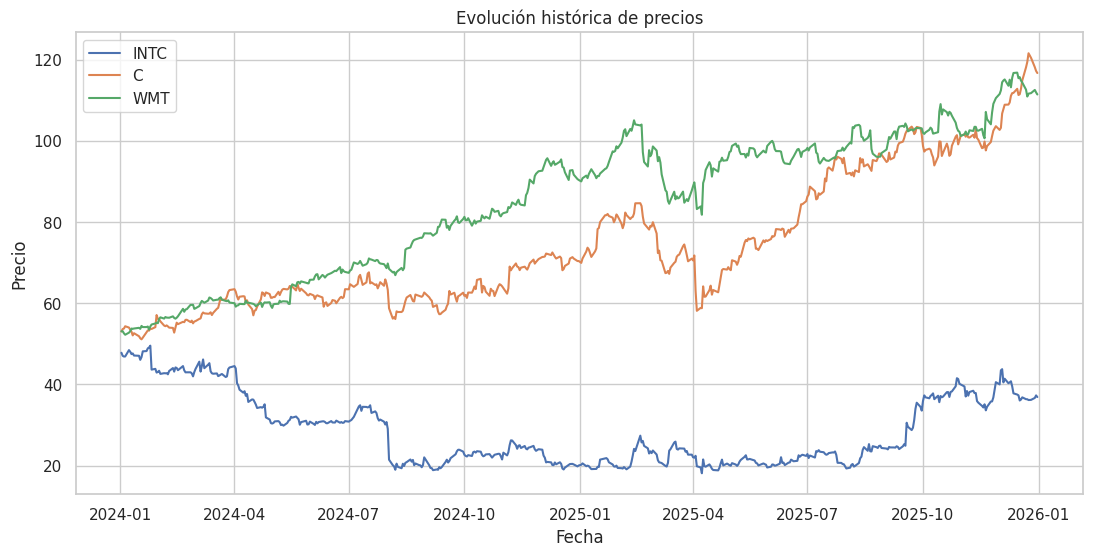

In [11]:
# 1. Extraer los precios de cierre

cierre = Precios["Close"]

cierre.head()

# 2. Graficar precios originales

fig, ax = plt.subplots(figsize=(13, 6))

for activo in activos:
    ax.plot(cierre.index, cierre[activo], label=activo)

ax.set_title("Evolución histórica de precios")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio")
ax.legend()

plt.show()



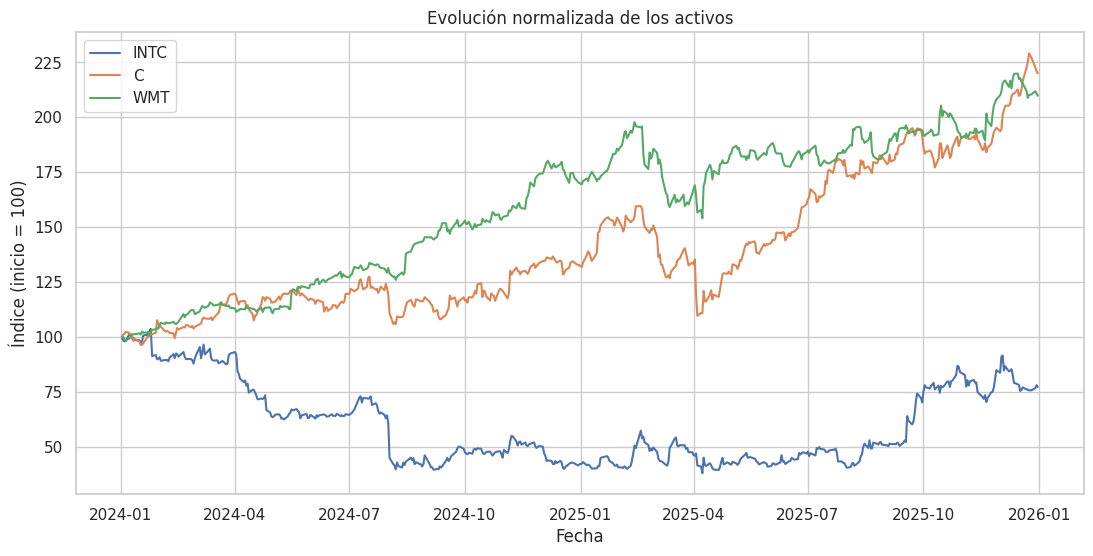

In [9]:
# 3. Normalizar y graficar en base 100

cierre_normalizado = cierre / cierre.iloc[0] * 100

cierre_normalizado.head()

fig, ax = plt.subplots(figsize=(13, 6))

for activo in activos:
    ax.plot(
        cierre_normalizado.index,
        cierre_normalizado[activo],
        label=activo
    )

ax.set_title("Evolución normalizada de los activos")
ax.set_xlabel("Fecha")
ax.set_ylabel("Índice (inicio = 100)")
ax.legend()

plt.show()

 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

R// Por que en el normalizado parten todos de una base de un mismo valor y ahi es mas facil saber cual de las tres a tenido mejor rendimiento historico por que mientras en el grafico temporal todas parten de diferente valor y es mas dificil saber cual a tenido mejor rendimiento historico por que no todos parten del mismo valor por lo que se puede hacer mas dificil para saber el rendimiento historico mientras en el normal ya sabes que el que es el mas alto es el que mejor rendimiento historico a tenido mientras si fuera en el temporal en el temporal pudo haber arrancado de un valor mas alto que los otros activos por lo que en el normalizado llegamos a la conclusion que el activo C osea citigroup es el que mas a crecido y de ahi le siga walmart y por ultimo intel

🔄 Paso 3: Cálculo y Distribución de Rendimientos

1.Calcula los rendimientos diarios de los activos y elimina los valores nulos (NaN).

2.Genera un *histograma para el activo que consideres que haya sido el más volátil.

3.Diseña un Boxplot comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:

¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

In [18]:
# PASO 3

# 1.calculos de los rendimientos

rendimientos = cierre.pct_change()

rendimientos.head()


rendimientos = rendimientos.dropna()

rendimientos.head()

Ticker,C,INTC,WMT
Date,,,
2024-01-03,0.011312,-0.015690,0.000063
2024-01-04,0.002424,-0.003826,-0.009667
2024-01-05,0.010415,0.000427,-0.006656
2024-01-08,-0.005890,0.033269,0.009827
2024-01-09,-0.009813,-0.008256,0.006698


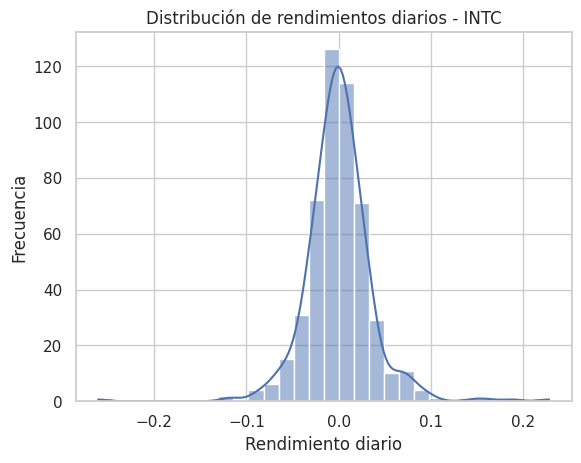

In [15]:
# 2. Histograma con el activo más volátil

sns.histplot(
    data=rendimientos,
    x="INTC",
    bins=30,
    kde=True
)

plt.title("Distribución de rendimientos diarios - INTC")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")

plt.show()


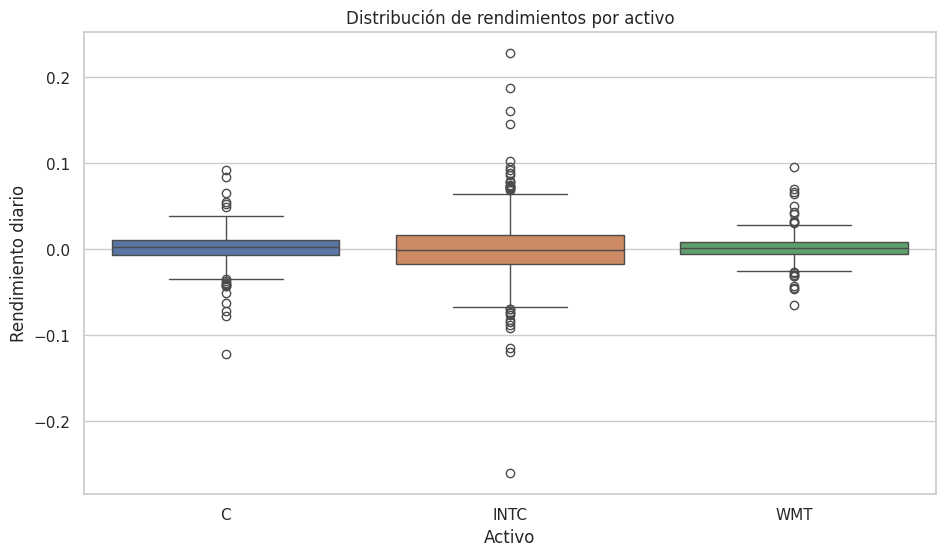

In [19]:
# 3.Diseña un Boxplot comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

plt.figure(figsize=(11, 6))

sns.boxplot(data=rendimientos)

plt.title("Distribución de rendimientos por activo")
plt.xlabel("Activo")
plt.ylabel("Rendimiento diario")

plt.show()

¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo? ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

R// El activo que presenta mas volatilidad o dispersion es el de INTC ya que ademas tiene el sector mas volatil que es el semi conductor sobre su riesgo es volatil por lo que nos dice que no es tan constante y puede tender a picos muy altos y si hay valores atipicos estas despues del 0.1 y -0.1 en adelante en el histograma estos valores atipicos representan el rendimiento maxiy minimo diario de el activo

## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

In [23]:
# 1. Calcular matriz de correlación

correlacion = rendimientos.corr()

correlacion

Ticker,C,INTC,WMT
Ticker,,,
C,1.000000,0.348785,0.269004
INTC,0.348785,1.000000,0.105924
WMT,0.269004,0.105924,1.000000


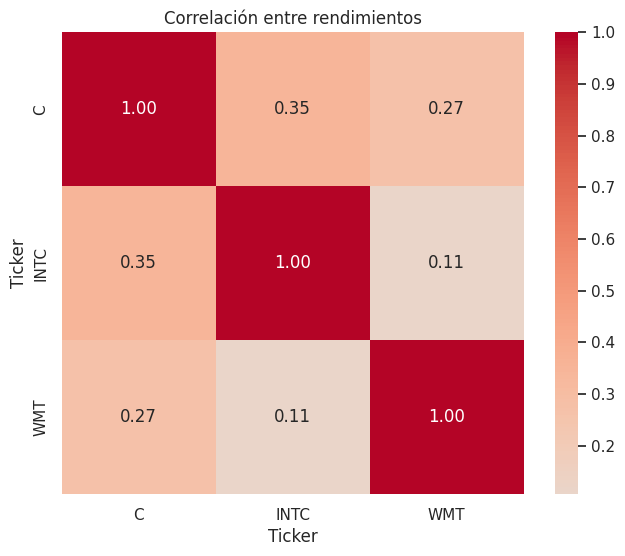

In [24]:
# 2. Dibujar el Heatmap utilizando Seaborn

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlación entre rendimientos")

plt.show()

Pregunta de interpretación #3:
¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?

R// No existe una correlaccion fuerte entre ninguno de mis tres activos del portafolio

Si tuvieras que armar un portafolio de inversión buscando la diversificación (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

R// Yo eligiria INTC y WMT segun la matriz de correlacion son las que menos correlacion tienen entre los 3 activos al ser de diferentes sectores al ser INTC del sector semiconductor y WMT del sector de consumo diario son las menos riesgosas para tener un riesgo conjunto por que tienen diferentes sectores




## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [ ]:
# Generar resumen de estadísticas descriptivas (Media, Mediana, Desviación estándar, Mínimo y Máximo)



In [25]:
resumen = pd.DataFrame({
    "Media": rendimientos.mean(),
    "Mediana": rendimientos.median(),
    "Desviación estándar": rendimientos.std(),
    "Mínimo": rendimientos.min(),
    "Máximo": rendimientos.max()
})

resumen


,Media,Mediana,Desviación estándar,Mínimo,Máximo
Ticker,,,,,
C,0.001743,0.002481,0.018281,-0.121377,0.091543
INTC,0.000151,-0.000826,0.036541,-0.260585,0.227711
WMT,0.001573,0.001330,0.013677,-0.065288,0.095488


Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

En conclusion segun en rendimientos y en volatilidad para mi la mejor opcion seria dejar el portafolio solo con el activo "C" que es el banco citigroup y el activo de "WMT" que es walmart por que "INTC" que es intel es el activo que mas volatilidad representa y el que menos rendimiento a generado teniendo una caida como vimos en el grafico normalizado cayendo por debajo de su base y ademas es la que mas riesgo representa al ser mas volatil y  tambien la que menos rendimiento diario genera al tener la menor media de los tres activos.

Por lo tanto mi portafolio lo dejaria solo con citigroup y walmart al ser de diferentes sectores uno del sector de bancos y el otro de consumo diario dan mayor mitigacion de riesgo conjunto